In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
import math

In [2]:
df_train = pd.read_csv(r"C:\Users\SEPEHR\Desktop\data_greenhouse.csv" , na_values="#")

In [3]:
df_train

,Indoor Humidity,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity,createdAt,updatedAt
0,91.4,27.5,54,34.2,-6.7,733,840,2021-08-22 04:32:53.464,2021-08-22 04:32:53.464
1,88.6,27.5,53,34.2,-6.7,674,831,2021-08-22 04:33:09.060,2021-08-22 04:33:09.060
2,92.6,27.4,53,33.9,-6.5,625,833,2021-08-22 04:33:24.763,2021-08-22 04:33:24.763
3,91.0,27.5,53,34.2,-6.7,584,858,2021-08-22 04:33:40.000,2021-08-22 04:33:40.000
4,91.1,27.4,54,33.9,-6.5,545,825,2021-08-22 04:33:55.281,2021-08-22 04:33:55.281
...,...,...,...,...,...,...,...,...,...
604129,84.3,26.9,91,14.2,12.7,258,2,2021-12-14 14:22:32.421,2021-12-14 14:22:32.421
604130,84.0,27.0,91,14.2,12.8,256,0,2021-12-14 14:22:47.133,2021-12-14 14:22:47.133
604131,84.1,27.0,91,14.2,12.8,257,0,2021-12-14 14:23:02.676,2021-12-14 14:23:02.676
604132,82.5,27.0,91,14.2,12.8,258,0,2021-12-14 14:23:19.176,2021-12-14 14:23:19.176


In [4]:
df_train.columns

Index(['Indoor Humidity', 'Indoor Temperature', 'Outdoor Humidity',
       'Outdoor Temperature', 'Temperature Difference', 'Indoor CO Saturation',
       'Indoor luminosity', 'createdAt', 'updatedAt'],
      dtype='object')

In [5]:
raw = df_train.loc[:,[ "Indoor Humidity" , "Indoor Temperature" , "Outdoor Humidity" , "Outdoor Temperature" , "Temperature Difference" , "Indoor CO Saturation" , "Indoor luminosity" ]]

In [6]:
raw

,Indoor Humidity,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
0,91.4,27.5,54,34.2,-6.7,733,840
1,88.6,27.5,53,34.2,-6.7,674,831
2,92.6,27.4,53,33.9,-6.5,625,833
3,91.0,27.5,53,34.2,-6.7,584,858
4,91.1,27.4,54,33.9,-6.5,545,825
...,...,...,...,...,...,...,...
604129,84.3,26.9,91,14.2,12.7,258,2
604130,84.0,27.0,91,14.2,12.8,256,0
604131,84.1,27.0,91,14.2,12.8,257,0
604132,82.5,27.0,91,14.2,12.8,258,0


In [7]:
raw.describe(include = "all")

,Indoor Humidity,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
count,604134.000000,604134.000000,604134.000000,604134.000000,604134.000000,604134.000000,604134.000000
mean,87.566299,25.058444,86.628382,18.999641,6.058803,318.841582,319.068448
std,15.479425,4.565374,15.047361,7.139967,5.026269,51.120569,363.885568
min,9.600000,8.600000,5.000000,2.500000,-15.000000,198.000000,0.000000
25%,75.100000,22.300000,88.000000,14.000000,2.300000,275.000000,0.000000
50%,96.200000,24.500000,91.000000,18.500000,4.600000,325.000000,7.000000
75%,99.900000,27.500000,93.000000,23.100000,9.800000,359.000000,721.000000
max,99.900000,45.500000,95.000000,45.000000,21.500000,908.000000,982.000000


# Data Preprocessing

In [10]:
from statistics import mode

Indoor Humidity

In [11]:
lst01 = list(raw['Indoor Humidity'].unique())
print("The number of unique values" , len(lst01))
print("min" , np.min(lst01))
print("max", np.max(lst01))
print("mode" , mode(lst01))

The number of unique values 797
min 9.6
max 99.9
mode 91.4


Indoor Temperature

In [12]:
lst02 = list(raw['Indoor Temperature'].unique())
print("The number of unique values" , len(lst02))
print("min" , np.min(lst02))
print("max", np.max(lst02))
print("mode" , mode(lst02))

The number of unique values 354
min 8.6
max 45.5
mode 27.5


Outdoor Humidity

In [13]:
lst03 = list(raw['Outdoor Humidity'].unique())
print("The number of unique values" , len(lst03))
print("min" , np.min(lst03))
print("max", np.max(lst03))
print("mode" , mode(lst03))

The number of unique values 91
min 5
max 95
mode 54


Outdoor Temperature

In [14]:
lst04 = list(raw['Outdoor Temperature'].unique())
print("The number of unique values" , len(lst04))
print("min" , np.min(lst04))
print("max", np.max(lst04))
print("mode" , mode(lst04))

The number of unique values 420
min 2.5
max 45.0
mode 34.2


Temperature Difference

In [15]:
lst05 = list(raw['Temperature Difference'].unique())
print("The number of unique values" , len(lst05))
print("min" , np.min(lst05))
print("max", np.max(lst05))
print("mode" , mode(lst05))

The number of unique values 1142
min -15.0
max 21.5
mode -6.700000000000003


Indoor CO Saturation

In [16]:
lst06 = list(raw['Indoor CO Saturation'].unique())
print("The number of unique values" , len(lst06))
print("min" , np.min(lst06))
print("max", np.max(lst06))
print("mode" , mode(lst06))

The number of unique values 534
min 198
max 908
mode 733


Indoor luminosity

In [18]:
lst07 = list(raw['Indoor luminosity'].unique())
print("The number of unique values" , len(lst07))
print("min" , np.min(lst07))
print("max", np.max(lst07))
print("mode" , mode(lst07))

The number of unique values 974
min 0
max 982
mode 840


# Data Representation

In [19]:
pd.DataFrame([[797 , 9.6 , 99.9 , 91.4] , [354 , 8.6 , 45.5 , 27.5] , [91 , 5.0 , 95.0 , 54.0] , [420 , 2.5 , 45.0 , 34.2] , [1142 , -15.0 , 21.5 , -6.700000000000003] , [534 , 198.0 , 908.0 , 733.0] , [974 , 0.0 , 982.0 , 840.0] ], index=['Indoor Humidity', 'Indoor Temperature', 'Outdoor Humidity','Outdoor Temperature', 'Temperature Difference', 'Indoor CO Saturation','Indoor luminosity']  ,columns= ["The number of unique values" , "Min" , "Max" , "Mode"])

,The number of unique values,Min,Max,Mode
Indoor Humidity,797,9.6,99.9,91.4
Indoor Temperature,354,8.6,45.5,27.5
Outdoor Humidity,91,5.0,95.0,54.0
Outdoor Temperature,420,2.5,45.0,34.2
Temperature Difference,1142,-15.0,21.5,-6.7
Indoor CO Saturation,534,198.0,908.0,733.0
Indoor luminosity,974,0.0,982.0,840.0


# Preprocessing

# Relation between Indoor Humidity (target) and other Variables

Text(0, 0.5, 'Indoor Temperature')

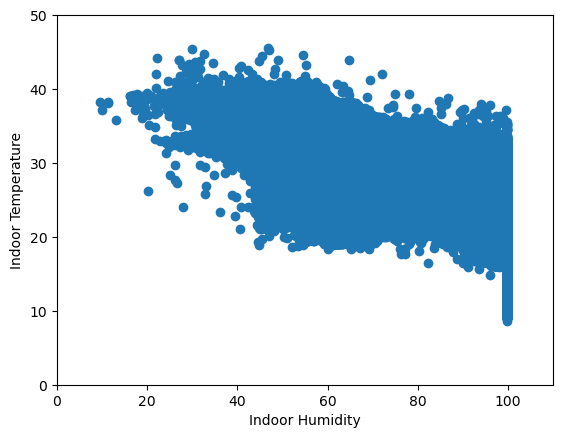

In [42]:
plt.scatter(raw["Indoor Humidity"] , raw["Indoor Temperature"] )
plt.ylim(0 , 50)
plt.xlim(0 , 110)
plt.xlabel("Indoor Humidity")
plt.ylabel("Indoor Temperature")

Text(0, 0.5, 'Outdoor Humidity')

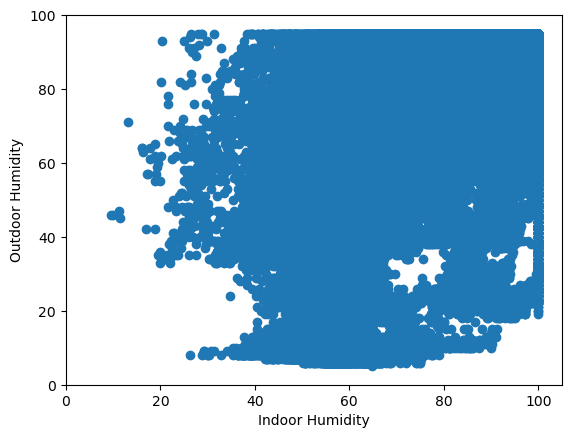

In [43]:
plt.scatter(raw["Indoor Humidity"] , raw["Outdoor Humidity"])
plt.ylim(0 , 100)
plt.xlim(0 , 105)
plt.xlabel("Indoor Humidity")
plt.ylabel("Outdoor Humidity")

Text(0, 0.5, 'Outdoor Temperature')

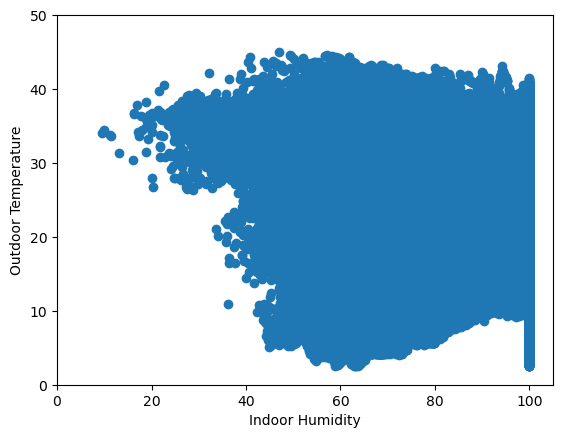

In [44]:
plt.scatter(raw["Indoor Humidity"] , raw["Outdoor Temperature"])
plt.ylim(0 , 50)
plt.xlim(0 , 105)
plt.xlabel("Indoor Humidity")
plt.ylabel("Outdoor Temperature")

Text(0, 0.5, 'Temperature Difference')

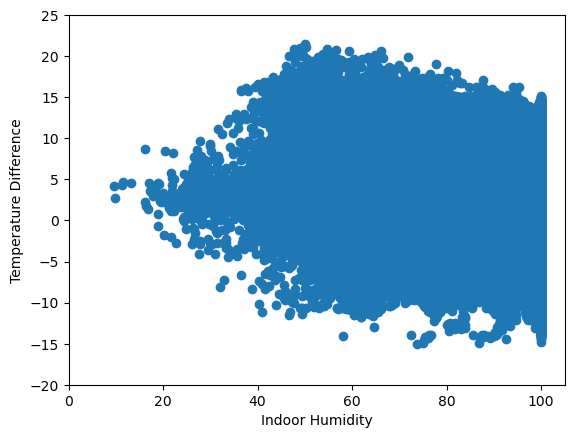

In [45]:
plt.scatter(raw["Indoor Humidity"] , raw["Temperature Difference"])
plt.ylim(-20 , 25)
plt.xlim(0 , 105)
plt.xlabel("Indoor Humidity")
plt.ylabel("Temperature Difference")

Text(0, 0.5, 'Indoor CO Saturation')

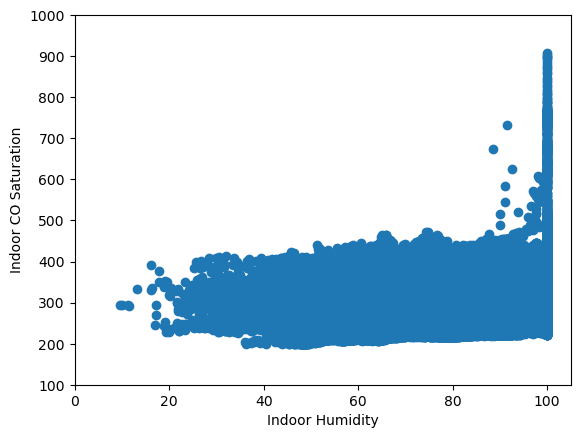

In [46]:
plt.scatter(raw["Indoor Humidity"] , raw["Indoor CO Saturation"])
plt.ylim(100 , 1000)
plt.xlim(0 , 105)
plt.xlabel("Indoor Humidity")
plt.ylabel("Indoor CO Saturation")

Text(0, 0.5, 'Indoor luminosity')

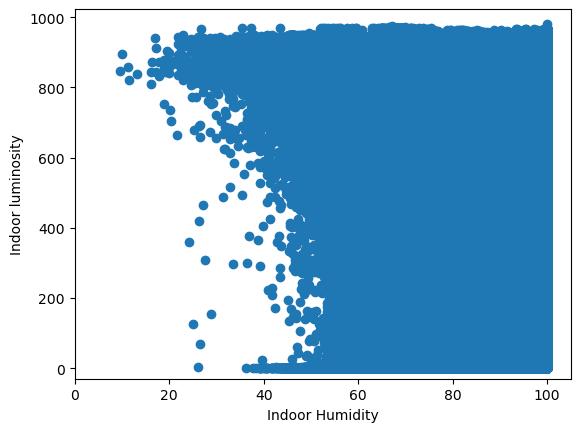

In [47]:
plt.scatter(raw["Indoor Humidity"] , raw["Indoor luminosity"])
plt.ylim(-30 , 1023)
plt.xlim(0 , 105)
plt.xlabel("Indoor Humidity")
plt.ylabel("Indoor luminosity")

# Data Normalization

In [9]:
raw.columns

Index(['Indoor Humidity', 'Indoor Temperature', 'Outdoor Humidity',
       'Outdoor Temperature', 'Temperature Difference', 'Indoor CO Saturation',
       'Indoor luminosity'],
      dtype='object')

Text(0.5, 0, 'Indoor Humidity')

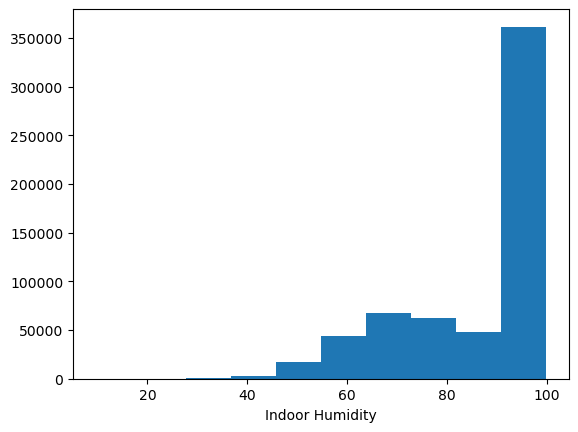

In [49]:
plt.hist(raw["Indoor Humidity"])
plt.xlabel("Indoor Humidity")

Text(0.5, 0, 'Indoor Temperature')

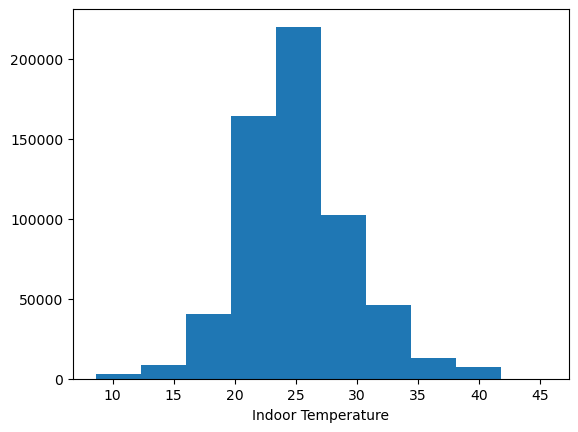

In [50]:
plt.hist(raw["Indoor Temperature"])
plt.xlabel("Indoor Temperature")

Text(0.5, 0, 'Outdoor Humidity')

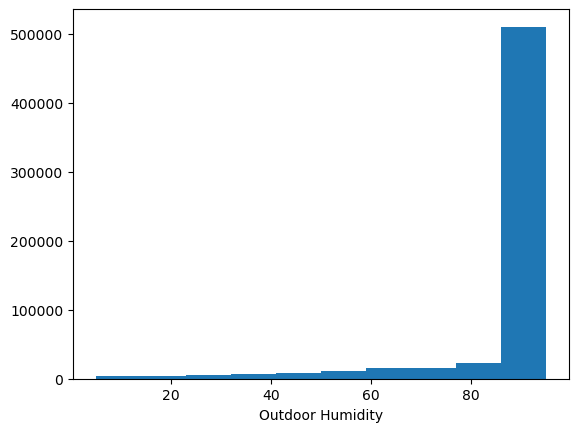

In [51]:
plt.hist(raw["Outdoor Humidity"])
plt.xlabel("Outdoor Humidity")

Text(0.5, 0, 'Outdoor Temperature')

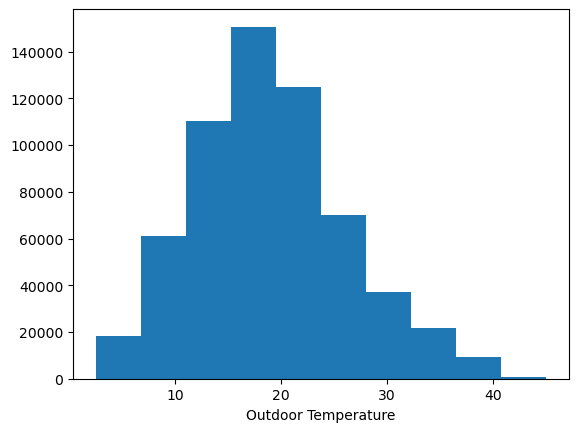

In [52]:
plt.hist(raw["Outdoor Temperature"])
plt.xlabel("Outdoor Temperature")

Text(0.5, 0, 'Temperature Difference')

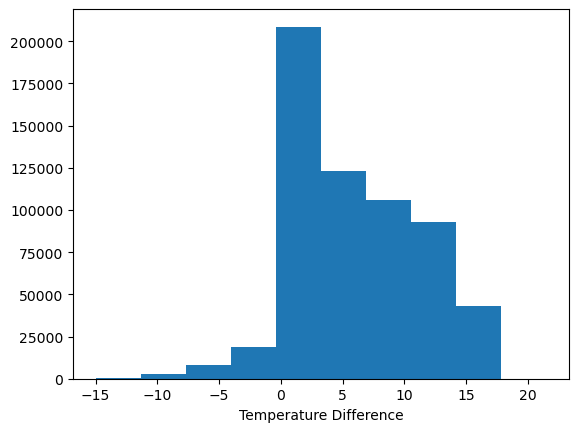

In [53]:
plt.hist(raw["Temperature Difference"])
plt.xlabel("Temperature Difference")

Text(0.5, 0, 'Indoor CO Saturation')

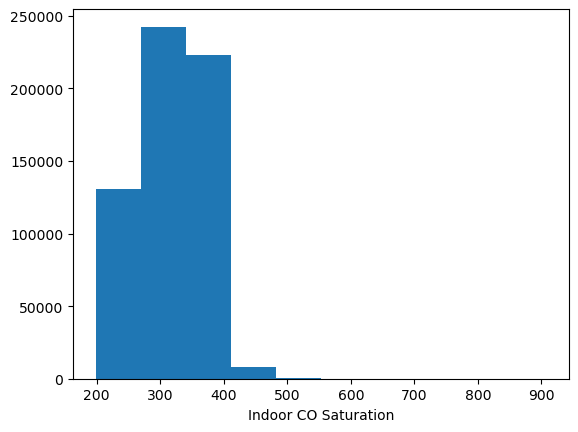

In [54]:
plt.hist(raw["Indoor CO Saturation"])
plt.xlabel("Indoor CO Saturation")

Text(0.5, 0, 'Indoor luminosity')

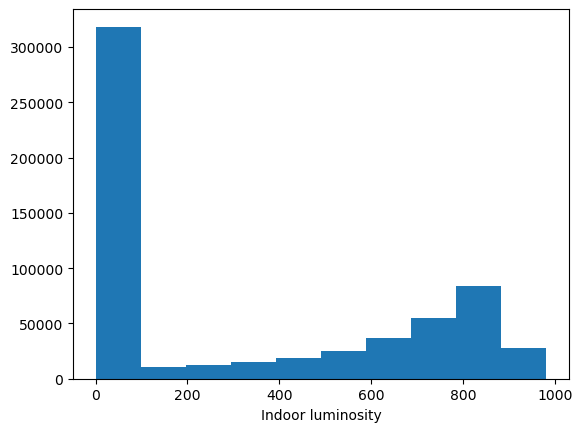

In [55]:
plt.hist(raw["Indoor luminosity"])
plt.xlabel("Indoor luminosity")

In [56]:
from sklearn.preprocessing import MinMaxScaler
raw_data = raw
raw_data

,Indoor Humidity,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
0,91.4,27.5,54,34.2,-6.7,733,840
1,88.6,27.5,53,34.2,-6.7,674,831
2,92.6,27.4,53,33.9,-6.5,625,833
3,91.0,27.5,53,34.2,-6.7,584,858
4,91.1,27.4,54,33.9,-6.5,545,825
...,...,...,...,...,...,...,...
604129,84.3,26.9,91,14.2,12.7,258,2
604130,84.0,27.0,91,14.2,12.8,256,0
604131,84.1,27.0,91,14.2,12.8,257,0
604132,82.5,27.0,91,14.2,12.8,258,0


In [57]:
df_min_max_scaled = raw
  
# apply normalization techniques
for column in df_min_max_scaled.columns:
    df_min_max_scaled[column] = (df_min_max_scaled[column] - df_min_max_scaled[column].min()) / (df_min_max_scaled[column].max() - df_min_max_scaled[column].min())    
  
# view normalized data
df_min_max_scaled

,Indoor Humidity,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
0,0.905869,0.512195,0.544444,0.745882,0.227397,0.753521,0.855397
1,0.874862,0.512195,0.533333,0.745882,0.227397,0.670423,0.846232
2,0.919158,0.509485,0.533333,0.738824,0.232877,0.601408,0.848269
3,0.901440,0.512195,0.533333,0.745882,0.227397,0.543662,0.873727
4,0.902547,0.509485,0.544444,0.738824,0.232877,0.488732,0.840122
...,...,...,...,...,...,...,...
604129,0.827243,0.495935,0.955556,0.275294,0.758904,0.084507,0.002037
604130,0.823920,0.498645,0.955556,0.275294,0.761644,0.081690,0.000000
604131,0.825028,0.498645,0.955556,0.275294,0.761644,0.083099,0.000000
604132,0.807309,0.498645,0.955556,0.275294,0.761644,0.084507,0.000000


Text(0.5, 0, 'Indoor CO Saturation')

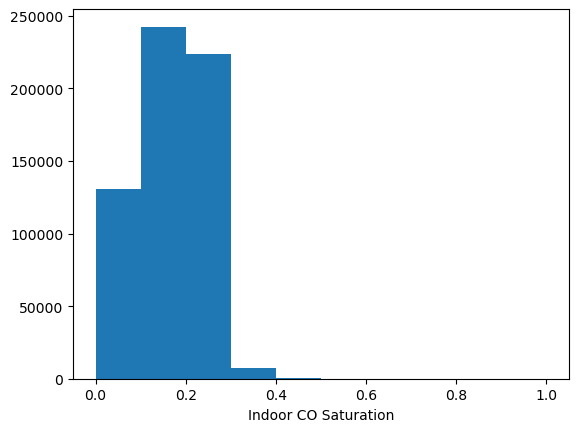

In [58]:
plt.hist(df_min_max_scaled["Indoor CO Saturation"])
plt.xlabel("Indoor CO Saturation")

Text(0.5, 0, 'Indoor luminosity')

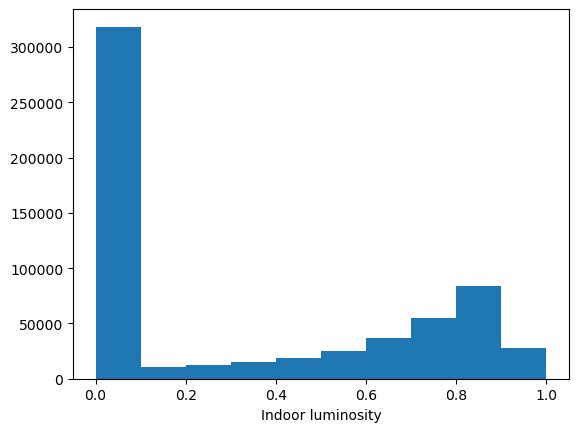

In [59]:
plt.hist(df_min_max_scaled["Indoor luminosity"])
plt.xlabel("Indoor luminosity")

([<matplotlib.axis.XTick at 0x1fd98ead7c0>,
 [Text(1, 0, 'Indoor Humidity'),
  Text(2, 0, 'Indoor Temperature'),
  Text(3, 0, 'Outdoor Humidity'),
  Text(4, 0, 'Outdoor Temperature'),
  Text(5, 0, 'Temperature Difference'),
  Text(6, 0, 'Indoor CO Saturation'),
  Text(7, 0, 'Indoor luminosity')])

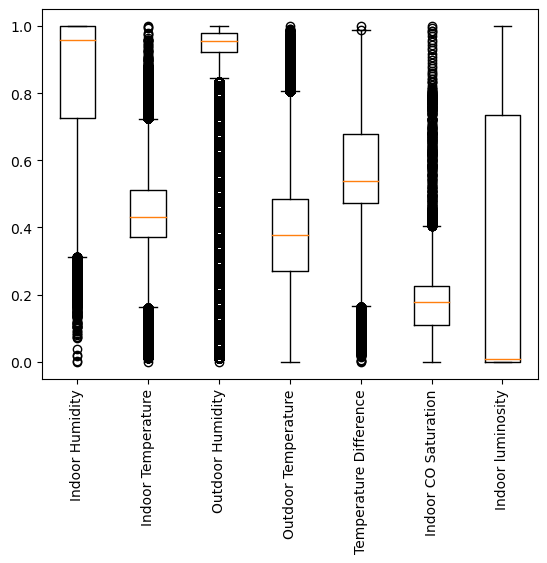

In [60]:
plt.boxplot(raw)
plt.xticks(range(1,8) , raw.columns , rotation = "90")

([<matplotlib.axis.XTick at 0x1fd97b77190>,
 [Text(1, 0, 'Indoor Humidity'),
  Text(2, 0, 'Indoor Temperature'),
  Text(3, 0, 'Outdoor Humidity'),
  Text(4, 0, 'Outdoor Temperature'),
  Text(5, 0, 'Temperature Difference'),
  Text(6, 0, 'Indoor CO Saturation'),
  Text(7, 0, 'Indoor luminosity')])

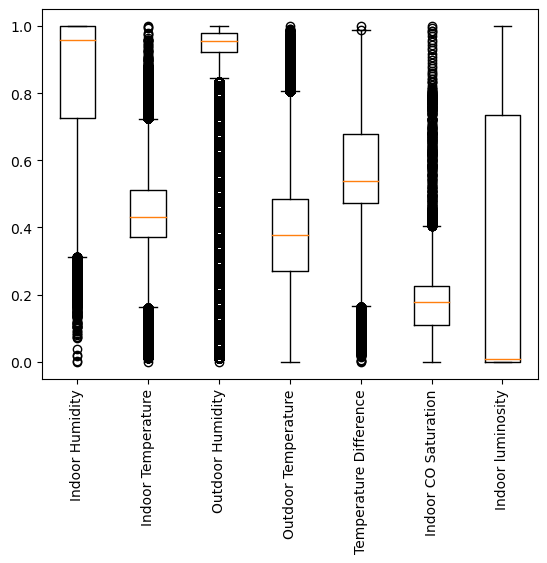

In [61]:
plt.boxplot(df_min_max_scaled)
plt.xticks(range(1,8) , raw_data.columns , rotation = "90")

In [62]:
raw_data

,Indoor Humidity,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
0,0.905869,0.512195,0.544444,0.745882,0.227397,0.753521,0.855397
1,0.874862,0.512195,0.533333,0.745882,0.227397,0.670423,0.846232
2,0.919158,0.509485,0.533333,0.738824,0.232877,0.601408,0.848269
3,0.901440,0.512195,0.533333,0.745882,0.227397,0.543662,0.873727
4,0.902547,0.509485,0.544444,0.738824,0.232877,0.488732,0.840122
...,...,...,...,...,...,...,...
604129,0.827243,0.495935,0.955556,0.275294,0.758904,0.084507,0.002037
604130,0.823920,0.498645,0.955556,0.275294,0.761644,0.081690,0.000000
604131,0.825028,0.498645,0.955556,0.275294,0.761644,0.083099,0.000000
604132,0.807309,0.498645,0.955556,0.275294,0.761644,0.084507,0.000000


Correlation between independent variables (correlation matrix)

<AxesSubplot:>

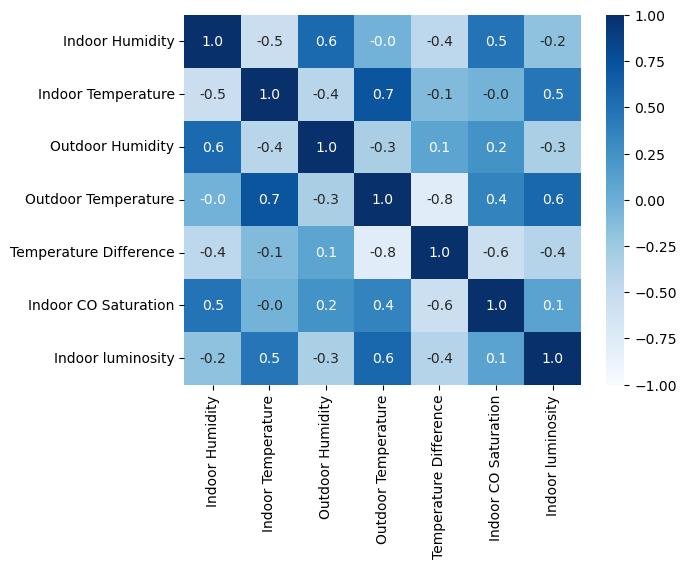

In [63]:
import seaborn as sns
correlation = raw_data.corr()
sns.heatmap(correlation , vmin= -1 , annot= True , fmt= ".1f" , cmap="Blues")

# Spliting Dataset

In [64]:
raw_data

,Indoor Humidity,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
0,0.905869,0.512195,0.544444,0.745882,0.227397,0.753521,0.855397
1,0.874862,0.512195,0.533333,0.745882,0.227397,0.670423,0.846232
2,0.919158,0.509485,0.533333,0.738824,0.232877,0.601408,0.848269
3,0.901440,0.512195,0.533333,0.745882,0.227397,0.543662,0.873727
4,0.902547,0.509485,0.544444,0.738824,0.232877,0.488732,0.840122
...,...,...,...,...,...,...,...
604129,0.827243,0.495935,0.955556,0.275294,0.758904,0.084507,0.002037
604130,0.823920,0.498645,0.955556,0.275294,0.761644,0.081690,0.000000
604131,0.825028,0.498645,0.955556,0.275294,0.761644,0.083099,0.000000
604132,0.807309,0.498645,0.955556,0.275294,0.761644,0.084507,0.000000


In [65]:
X = raw_data.loc[:,['Indoor Temperature', 'Outdoor Humidity','Outdoor Temperature', 'Temperature Difference', 'Indoor CO Saturation','Indoor luminosity']]
y = raw_data.loc[:,"Indoor Humidity"]
X_train , X_test , y_train , y_test = train_test_split(X, y , test_size=0.2, random_state=0)

In [66]:
X_train

,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
411920,0.449864,0.966667,0.327059,0.652055,0.112676,0.130346
49535,0.680217,0.588889,0.795294,0.339726,0.267606,0.885947
491934,0.663957,0.577778,0.334118,0.860274,0.077465,0.577393
98366,0.344173,0.977778,0.390588,0.471233,0.246479,0.016293
551179,0.308943,0.911111,0.049412,0.832877,0.209859,0.192464
...,...,...,...,...,...,...
359783,0.395664,0.966667,0.360000,0.558904,0.090141,0.002037
152315,0.411924,0.988889,0.447059,0.473973,0.304225,0.000000
117952,0.487805,1.000000,0.529412,0.454795,0.226761,0.510183
435829,0.666667,0.200000,0.444706,0.734247,0.046479,0.701629


In [67]:
X_test

,Indoor Temperature,Outdoor Humidity,Outdoor Temperature,Temperature Difference,Indoor CO Saturation,Indoor luminosity
577878,0.439024,0.944444,0.235294,0.747945,0.053521,0.000000
523286,0.406504,0.922222,0.171765,0.789041,0.218310,0.000000
197345,0.308943,0.966667,0.345882,0.487671,0.178873,0.000000
15867,0.536585,1.000000,0.560000,0.468493,0.183099,0.000000
289200,0.338753,0.955556,0.258824,0.619178,0.198592,0.684318
...,...,...,...,...,...,...
246681,0.260163,0.955556,0.308235,0.482192,0.170423,0.491853
534020,0.284553,0.788889,0.282353,0.536986,0.183099,0.000000
320397,0.384824,0.977778,0.402353,0.498630,0.276056,0.000000
411753,0.455285,0.966667,0.341176,0.641096,0.108451,0.075356


# Models

# Multiple regression

In [98]:
reg = LinearRegression()
reg.fit(X_train , y_train)

LinearRegression()

In [99]:
y_pred = reg.predict(X_test)
print(y_pred)

[0.7605432  0.78408487 1.02793527 ... 1.00767995 0.8361517  0.54907521]


In [100]:
# Testing Dataset
print(r2_score(y_test,y_pred))
print(mean_squared_error(y_test,y_pred , squared=True))
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred , squared=False))

0.7074740811048379
0.008626136394413996
0.07147881574667979
0.09287699604538249


In [101]:
# Training Dataset
y_predict = reg.predict(X_train)
print(y_predict)
print(r2_score(y_train,y_predict))
print(mean_squared_error(y_train,y_predict , squared=True))
print(mean_absolute_error(y_train,y_predict))
print(mean_squared_error(y_train,y_predict , squared=False))

[0.83187392 0.75796348 0.4111523  ... 0.95996786 0.32292938 0.92846028]
0.7080669092639607
0.008571086056116884
0.07133340629487071
0.09258016016467505


# Polynomial Regression

In [102]:
#Training Dataset
poly = PolynomialFeatures(degree=3)
x_train_trans = poly.fit_transform(X_train)
x_test_trans = poly.transform(X_test)
#include bias parameter
lr = LinearRegression()
lr.fit(x_train_trans, y_train)
y_pred = lr.predict(x_test_trans)

#Testing Dataset
print(r2_score(y_test,y_pred))
print(mean_squared_error(y_test,y_pred , squared=True))
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test, y_pred , squared=False))

0.8365766803783667
0.004819100647246736
0.04534562868735758
0.0694197424890552


In [103]:
#Training Dataset
y_mim = lr.predict(x_train_trans)
print(r2_score(y_train,y_mim))
print(mean_squared_error(y_train,y_mim , squared=True))
print(mean_absolute_error(y_train,y_mim))
print(mean_squared_error(y_train, y_mim , squared=False))

0.8378678350125974
0.004760161772233158
0.04509020043189725
0.0689939256183699


# SVR

In [217]:
from sklearn.svm import SVR

In [218]:
LL_svr = SVR(kernel = 'rbf')
LL_svr.fit(X_train,y_train)
y_pred = LL_svr.predict(X_train)

#Training dataset
print(r2_score(y_train,y_pred))
print(mean_squared_error(y_train,y_pred , squared=True))
print(mean_absolute_error(y_train,y_pred))
print(mean_squared_error(y_train,y_pred , squared=False))

0.8241457950292883
0.005163037599930138
0.056637763906828925
0.07185428031739055


In [219]:
#Testing dataset
y_predd = LL_svr.predict(X_test)
print(r2_score(y_test,y_predd))
print(mean_squared_error(y_test,y_predd , squared=True))
print(mean_absolute_error(y_test,y_predd))
print(mean_squared_error(y_test,y_predd , squared=False))

0.8230743478882505
0.005217263525060693
0.05677627773406832
0.07223062733398272


# Random Forest Regression

In [104]:
from sklearn.ensemble import RandomForestRegressor

In [163]:
regressor = RandomForestRegressor(n_estimators = 100,   random_state = 0)
regressor.fit(X_train, y_train)
y_pred = regressor.predict(X_train)
print(y_pred)

#Training dataset
print(r2_score(y_train,y_pred))
print(mean_squared_error(y_train,y_pred , squared=True))
print(mean_absolute_error(y_train,y_pred))
print(mean_squared_error(y_train,y_pred , squared=False))

[0.94940938 0.82083056 0.46716501 ... 0.97704319 0.46285714 1.        ]
0.9928230864880212
0.00021071247241409382
0.006067261353151373
0.014515938564698247


In [164]:
#Testing dataset
y_pred = regressor.predict(X_test)
print(y_pred)
print(r2_score(y_test,y_pred))
print(mean_squared_error(y_test,y_pred , squared=True))
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred , squared=False))

[0.72999408 0.61814784 1.         ... 1.         0.95218162 0.48420819]
0.9622045274313002
0.0011145299626792433
0.014239272516678553
0.033384576718587335


# K Nearest Neighbor Regression

In [107]:
from sklearn.neighbors import KNeighborsRegressor

In [166]:
# The best hyperparameters :)
clf=KNeighborsRegressor(7)
clf.fit(X_train,y_train)
y_prediction = clf.predict(X_train)

#Training dataset
print(r2_score(y_train,y_prediction))
print(mean_squared_error(y_train,y_prediction, squared=True))
print(mean_absolute_error(y_train,y_prediction))
print(mean_squared_error(y_train,y_prediction , squared=False))

0.9721108820493188
0.0008188178646750866
0.012024339717335974
0.028614993703914852


In [167]:
#Testing dataset
y_ss = clf.predict(X_test)
print(r2_score(y_test,y_ss))
print(mean_squared_error(y_test,y_ss, squared=True))
print(mean_absolute_error(y_test,y_ss))
print(mean_squared_error(y_test,y_ss , squared=False))

0.9616228353327232
0.0011316831619609699
0.014099094877914666
0.03364049883638722


# Decision Tree Regression

In [131]:
from sklearn.tree import DecisionTreeRegressor

In [212]:
# The best hyperparameters :)
LL_dt = DecisionTreeRegressor(max_depth=20)
LL_dt.fit(X_train,y_train)
ytrain_pred = LL_dt.predict(X_train)

#Training dataset
print(r2_score(y_train,ytrain_pred))
print(mean_squared_error(y_train,ytrain_pred, squared=False))
print(mean_absolute_error(y_train,ytrain_pred))
print(mean_squared_error(y_train,ytrain_pred, squared=True))

0.9832038747567804
0.02220653595708567
0.008901466383365671
0.0004931302392133389


In [213]:
#Testing dataset
ytrain = LL_dt.predict(X_test)
print(r2_score(y_test,ytrain))
print(mean_squared_error(y_test,ytrain, squared=False))
print(mean_absolute_error(y_test,ytrain))
print(mean_squared_error(y_test,ytrain, squared=True))

0.9440636398000641
0.04061374950875942
0.016265774957850518
0.0016494766491602563


# XGBOOST

In [ ]:
! pip install xgboost

In [156]:
import xgboost as xg

In [157]:
xgb_r = xg.XGBRegressor(objective = 'reg:squarederror' , n_estimators = 150 , max_depth=13 , eta= 0.2)

#Testing dataset
xgb_r.fit(X_train, y_train)
simba = xgb_r.predict(X_test)
print(r2_score(y_test,simba))
print(mean_squared_error(y_test,simba, squared=False))
print(mean_absolute_error(y_test,simba))
print(mean_squared_error(y_test,simba, squared=True))

0.9623512099072736
0.033319731745458
0.01499442661149069
0.0011102045235892818


In [158]:
#Training dataset
simba = xgb_r.predict(X_train)
print(r2_score(y_train,simba))
print(mean_squared_error(y_train,simba, squared=False))
print(mean_absolute_error(y_train,simba))
print(mean_squared_error(y_train,simba, squared=True))

0.986201167046763
0.020127852618083177
0.009735701401243522
0.0004051304510152778


# Ensemble Learning (Stacking)


# KNN + DT + RF + XGBoost

In [182]:
from sklearn.ensemble import VotingRegressor

In [183]:
from sklearn.ensemble import StackingRegressor

Testing Dataset

In [184]:
model = StackingRegressor([('KNR',clf) , ('DTR',LL_dt) , ('RFR',regressor) , ('XGBOOST',xgb_r)])
model.fit(X_train,y_train)
model_p = model.predict(X_test)
print(r2_score(y_test,model_p))
print(mean_squared_error(y_test,model_p, squared=False))
print(mean_absolute_error(y_test,model_p))
print(mean_squared_error(y_test,model_p, squared=True))

0.9651565430780178
0.03205432252015159
0.013950298848504497
0.0010274795922258976


Training Dataset

In [185]:
model_pi = model.predict(X_train)
print(r2_score(y_train,model_pi))
print(mean_squared_error(y_train,model_pi, squared=False))
print(mean_absolute_error(y_train,model_pi))
print(mean_squared_error(y_train,model_pi, squared=True))

0.986233595189131
0.02010418783423295
0.009119422071501643
0.00040417836847412013


# MLP-NN (Petrakis et al [36])

# Related Studies (MLP-NN) -- But we just used its dataset :)

In [187]:
New_DS = pd.read_csv(r"F:\dataset.csv" , na_values="#" ,sep=';')

In [188]:
New_DS

,TIMESTAMP,Tair_Avg,RH_Avg,WS_Avg,SolRad_Out_Avg,Tair_in_1_Avg,RH_in_1_Avg,Tair_in_2_Avg,RH_in_2_Avg,Tin_Avg,RHin_Avg
0,2022-02-14 14:10:00,17.04,49.55,1.223,460.70,38.57,16.69,38.96,22.38,38.765,19.535
1,2022-02-14 14:20:00,16.49,50.71,0.855,196.20,35.26,20.94,36.23,25.41,35.745,23.175
2,2022-02-14 14:30:00,15.56,55.32,1.540,492.60,33.23,21.73,33.93,27.11,33.580,24.420
3,2022-02-14 14:40:00,15.85,53.97,0.872,398.40,33.94,20.58,34.42,26.09,34.180,23.335
4,2022-02-14 14:50:00,15.63,55.35,0.876,279.10,32.21,24.02,33.57,27.49,32.890,25.755
...,...,...,...,...,...,...,...,...,...,...,...
9032,2022-04-18 07:30:00,12.09,78.01,3.929,23.21,13.62,65.82,14.18,70.09,13.900,67.955
9033,2022-04-18 07:40:00,12.16,75.58,3.799,33.85,13.93,63.19,14.44,67.88,14.185,65.535
9034,2022-04-18 07:50:00,12.38,74.04,3.798,40.36,14.28,61.11,14.81,65.83,14.545,63.470
9035,2022-04-18 08:00:00,12.53,74.48,3.693,44.94,14.56,60.17,15.18,64.65,14.870,62.410


In [189]:
New_DS.dropna(axis= 0 , inplace=True)

In [190]:
New_DS

,TIMESTAMP,Tair_Avg,RH_Avg,WS_Avg,SolRad_Out_Avg,Tair_in_1_Avg,RH_in_1_Avg,Tair_in_2_Avg,RH_in_2_Avg,Tin_Avg,RHin_Avg
0,2022-02-14 14:10:00,17.04,49.55,1.223,460.70,38.57,16.69,38.96,22.38,38.765,19.535
1,2022-02-14 14:20:00,16.49,50.71,0.855,196.20,35.26,20.94,36.23,25.41,35.745,23.175
2,2022-02-14 14:30:00,15.56,55.32,1.540,492.60,33.23,21.73,33.93,27.11,33.580,24.420
3,2022-02-14 14:40:00,15.85,53.97,0.872,398.40,33.94,20.58,34.42,26.09,34.180,23.335
4,2022-02-14 14:50:00,15.63,55.35,0.876,279.10,32.21,24.02,33.57,27.49,32.890,25.755
...,...,...,...,...,...,...,...,...,...,...,...
9032,2022-04-18 07:30:00,12.09,78.01,3.929,23.21,13.62,65.82,14.18,70.09,13.900,67.955
9033,2022-04-18 07:40:00,12.16,75.58,3.799,33.85,13.93,63.19,14.44,67.88,14.185,65.535
9034,2022-04-18 07:50:00,12.38,74.04,3.798,40.36,14.28,61.11,14.81,65.83,14.545,63.470
9035,2022-04-18 08:00:00,12.53,74.48,3.693,44.94,14.56,60.17,15.18,64.65,14.870,62.410


In [191]:
DS_New = New_DS.loc[:,['Tair_Avg', 'RH_Avg', 'WS_Avg', 'SolRad_Out_Avg','Tair_in_1_Avg', 'RH_in_1_Avg', 'Tair_in_2_Avg', 'RH_in_2_Avg','Tin_Avg', 'RHin_Avg']]

In [192]:
sas = DS_New
  
# apply normalization techniques
for column in sas.columns:
    sas[column] = (sas[column] - sas[column].min()) / (sas[column].max() - sas[column].min())    
  
# view normalized data
sas

,Tair_Avg,RH_Avg,WS_Avg,SolRad_Out_Avg,Tair_in_1_Avg,RH_in_1_Avg,Tair_in_2_Avg,RH_in_2_Avg,Tin_Avg,RHin_Avg
0,0.619274,0.404509,0.193543,0.456139,0.769477,0.160054,0.718767,0.173094,0.749017,0.165590
1,0.597115,0.418201,0.135306,0.194257,0.698299,0.210467,0.663091,0.209554,0.685322,0.209126
2,0.559647,0.472616,0.243709,0.487723,0.654646,0.219838,0.616185,0.230010,0.639660,0.224016
3,0.571331,0.456681,0.137997,0.394455,0.669914,0.206197,0.626178,0.217737,0.652314,0.211039
4,0.562467,0.472970,0.138630,0.276337,0.632712,0.247002,0.608843,0.234583,0.625107,0.239983
...,...,...,...,...,...,...,...,...,...,...
9032,0.419846,0.740439,0.621776,0.022980,0.232953,0.742832,0.213403,0.747187,0.224588,0.744708
9033,0.422666,0.711756,0.601203,0.033515,0.239619,0.711635,0.218705,0.720594,0.230599,0.715764
9034,0.431530,0.693579,0.601044,0.039960,0.247145,0.686963,0.226251,0.695927,0.238192,0.691066
9035,0.437573,0.698772,0.584428,0.044495,0.253166,0.675812,0.233797,0.681728,0.245046,0.678388


In [193]:
sas.iloc[5271,:]

Tair_Avg          0.224165
RH_Avg            0.825307
WS_Avg            0.003165
SolRad_Out_Avg    0.000000
Tair_in_1_Avg     0.141346
RH_in_1_Avg       0.750305
Tair_in_2_Avg     0.136314
RH_in_2_Avg       0.744059
Tin_Avg           0.139802
RHin_Avg          0.746920
Name: 5708, dtype: float64

In [194]:
4983 + 288

5271

In [195]:
lst66 = []
for i in range(4983,5272):
    lst66.append(i) 
DS_test = DS_New.iloc[lst66,:]
DS_New.drop(lst66, axis = 0 , inplace=True)


In [196]:
DS_test

,Tair_Avg,RH_Avg,WS_Avg,SolRad_Out_Avg,Tair_in_1_Avg,RH_in_1_Avg,Tair_in_2_Avg,RH_in_2_Avg,Tin_Avg,RHin_Avg
5420,0.032714,0.686733,0.142902,0.0,0.037223,0.714482,0.039728,0.701462,0.038797,0.707690
5421,0.025140,0.694287,0.110619,0.0,0.035439,0.719820,0.038422,0.704230,0.037247,0.711757
5422,0.016397,0.701251,0.045260,0.0,0.033374,0.723972,0.035771,0.710968,0.034863,0.717199
5423,0.010314,0.706445,0.000000,0.0,0.030041,0.730615,0.032121,0.718669,0.031341,0.724375
5424,0.013859,0.711048,0.012344,0.0,0.026106,0.734292,0.027838,0.724686,0.027197,0.729219
...,...,...,...,...,...,...,...,...,...,...
5704,0.236332,0.792257,0.091945,0.0,0.154033,0.737969,0.148958,0.725287,0.152562,0.731372
5705,0.226623,0.801700,0.108403,0.0,0.148872,0.743663,0.144063,0.733349,0.147500,0.738249
5706,0.220136,0.811143,0.121380,0.0,0.145001,0.747221,0.139985,0.737080,0.143493,0.741897
5707,0.227267,0.825307,0.129293,0.0,0.142206,0.750424,0.137333,0.740569,0.140751,0.745246


In [197]:
DS_train = DS_New

In [198]:
DS_train

,Tair_Avg,RH_Avg,WS_Avg,SolRad_Out_Avg,Tair_in_1_Avg,RH_in_1_Avg,Tair_in_2_Avg,RH_in_2_Avg,Tin_Avg,RHin_Avg
0,0.619274,0.404509,0.193543,0.456139,0.769477,0.160054,0.718767,0.173094,0.749017,0.165590
1,0.597115,0.418201,0.135306,0.194257,0.698299,0.210467,0.663091,0.209554,0.685322,0.209126
2,0.559647,0.472616,0.243709,0.487723,0.654646,0.219838,0.616185,0.230010,0.639660,0.224016
3,0.571331,0.456681,0.137997,0.394455,0.669914,0.206197,0.626178,0.217737,0.652314,0.211039
4,0.562467,0.472970,0.138630,0.276337,0.632712,0.247002,0.608843,0.234583,0.625107,0.239983
...,...,...,...,...,...,...,...,...,...,...
9032,0.419846,0.740439,0.621776,0.022980,0.232953,0.742832,0.213403,0.747187,0.224588,0.744708
9033,0.422666,0.711756,0.601203,0.033515,0.239619,0.711635,0.218705,0.720594,0.230599,0.715764
9034,0.431530,0.693579,0.601044,0.039960,0.247145,0.686963,0.226251,0.695927,0.238192,0.691066
9035,0.437573,0.698772,0.584428,0.044495,0.253166,0.675812,0.233797,0.681728,0.245046,0.678388


In [199]:
DS_train.columns
DS_train_x = DS_train.loc[:,['Tair_Avg', 'RH_Avg', 'WS_Avg', 'SolRad_Out_Avg','Tair_in_1_Avg', 'RH_in_1_Avg', 'Tair_in_2_Avg', 'RH_in_2_Avg']]
DS_train_y = DS_train.loc[:,['RHin_Avg']]
DS_test_x = DS_test.loc[:,['Tair_Avg', 'RH_Avg', 'WS_Avg', 'SolRad_Out_Avg','Tair_in_1_Avg', 'RH_in_1_Avg', 'Tair_in_2_Avg', 'RH_in_2_Avg']]
DS_test_y = DS_test.loc[:,['RHin_Avg']]

# XGBoost

In [200]:
boost = xg.XGBRegressor(objective = 'reg:squarederror' , n_estimators = 150 , max_depth=13 , eta= 0.2)
#Test
boost.fit(DS_train_x, DS_train_y)
sams = boost.predict(DS_test_x)
print(r2_score(DS_test_y,sams))
print(mean_squared_error(DS_test_y,sams, squared=False))
print(mean_absolute_error(DS_test_y,sams))
print(mean_squared_error(DS_test_y,sams, squared=True))

0.9999957844114681
0.00045879219470390997
0.0003426330720787369
2.104902779212304e-07


# DT

In [214]:
DTRM = DecisionTreeRegressor(max_depth=20)
DTRM.fit(DS_train_x,DS_train_y)
y_predicted = DTRM.predict(DS_test_x)
print(r2_score(DS_test_y,y_predicted))
print(mean_squared_error(DS_test_y,y_predicted, squared=False))
print(mean_absolute_error(DS_test_y,y_predicted))
print(mean_squared_error(DS_test_y,y_predicted, squared=True))

1.0
0.0
0.0
0.0


# Random Forest

In [215]:
RFR = RandomForestRegressor(n_estimators = 100,   random_state = 0)
RFR.fit(DS_train_x,DS_train_y)
y_pred_y = RFR.predict(DS_test_x)
print(y_pred)
print(r2_score(DS_test_y,y_pred_y))
print(mean_squared_error(DS_test_y,y_pred_y , squared=True))
print(mean_absolute_error(DS_test_y,y_pred_y))
print(mean_squared_error(DS_test_y,y_pred_y , squared=False))

C:\Users\SEPEHR\AppData\Local\Temp\ipykernel_114700\65927474.py:2: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  RFR.fit(DS_train_x,DS_train_y)


[0.72999408 0.61814784 1.         ... 1.         0.95218162 0.48420819]
0.9999570344638227
2.1453297878729418e-06
0.0004391879168772099
0.0014646944349839463


# KNRR

In [204]:
KNRR = KNeighborsRegressor(7)
KNRR.fit(DS_train_x,DS_train_y)
y_prediction_y = KNRR.predict(DS_test_x)
print(r2_score(DS_test_y,y_prediction_y))
print(mean_squared_error(DS_test_y,y_prediction_y, squared=True))
print(mean_absolute_error(DS_test_y,y_prediction_y))
print(mean_squared_error(DS_test_y,y_prediction_y , squared=False))

0.99836743582532
8.151623059238434e-05
0.0063932578244577975
0.009028633927255237


# Performance of our proposed Metamodel on Petrakis et al's studied testing dataset

In [216]:
meta_model = StackingRegressor([('KNR',KNRR) , ('DTR',DTRM) ,('RFR',RFR) , ('XGBOOST',boost)])
meta_model.fit(DS_train_x,DS_train_y)
meta_model_prediction = meta_model.predict(DS_test_x)
print(r2_score(DS_test_y,meta_model_prediction))
print(mean_squared_error(DS_test_y,meta_model_prediction, squared=False))
print(mean_absolute_error(DS_test_y,meta_model_prediction))
print(mean_squared_error(DS_test_y,meta_model_prediction, squared=True))

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\ensemble\_stacking.py:758: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


0.999938826030423
0.0017477135163164765
0.0015679249660979348
3.054502535115303e-06
